In [2]:
from sklearn.datasets import load_diabetes

In [3]:
dataset = load_diabetes()

In [4]:
print(dataset.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [5]:
dataset.feature_names

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

In [6]:
import pandas as pd
df_diabetes = pd.DataFrame(dataset.data, columns=dataset.feature_names)


In [7]:
X = df_diabetes
y = dataset['target']

In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

In [9]:
X_train.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
249,-0.012780,-0.044642,0.060618,0.052858,0.047965,0.029375,-0.017629,0.034309,0.070207,0.007207
389,-0.005515,0.050680,0.001339,-0.084856,-0.011201,-0.016658,0.048640,-0.039493,-0.041176,-0.088062
121,0.063504,-0.044642,0.017506,0.021872,0.008063,0.021546,-0.036038,0.034309,0.019907,0.011349
195,0.027178,0.050680,0.025051,0.014987,0.025950,0.048477,-0.039719,0.034309,0.007838,0.023775
69,0.016281,-0.044642,-0.046085,-0.005670,-0.075870,-0.061438,-0.013948,-0.039493,-0.051404,0.019633


In [10]:
X_train.corr()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
age,1.000000,0.197408,0.198359,0.394903,0.238375,0.192920,-0.128403,0.227110,0.314151,0.351570
sex,0.197408,1.000000,0.108261,0.221914,0.057674,0.180315,-0.379464,0.324882,0.150956,0.193322
bmi,0.198359,0.108261,1.000000,0.356324,0.226047,0.248146,-0.395021,0.412826,0.435505,0.358273
bp,0.394903,0.221914,0.356324,1.000000,0.238295,0.165632,-0.192505,0.249141,0.420236,0.368882
s1,0.238375,0.057674,0.226047,0.238295,1.000000,0.872781,0.006313,0.559626,0.566312,0.356280
s2,0.192920,0.180315,0.248146,0.165632,0.872781,1.000000,-0.265114,0.684840,0.325759,0.315890
s3,-0.128403,-0.379464,-0.395021,-0.192505,0.006313,-0.265114,1.000000,-0.754616,-0.370523,-0.297055
s4,0.227110,0.324882,0.412826,0.249141,0.559626,0.684840,-0.754616,1.000000,0.609983,0.436311
s5,0.314151,0.150956,0.435505,0.420236,0.566312,0.325759,-0.370523,0.609983,1.000000,0.490970
s6,0.351570,0.193322,0.358273,0.368882,0.356280,0.315890,-0.297055,0.436311,0.490970,1.000000


<Axes: >

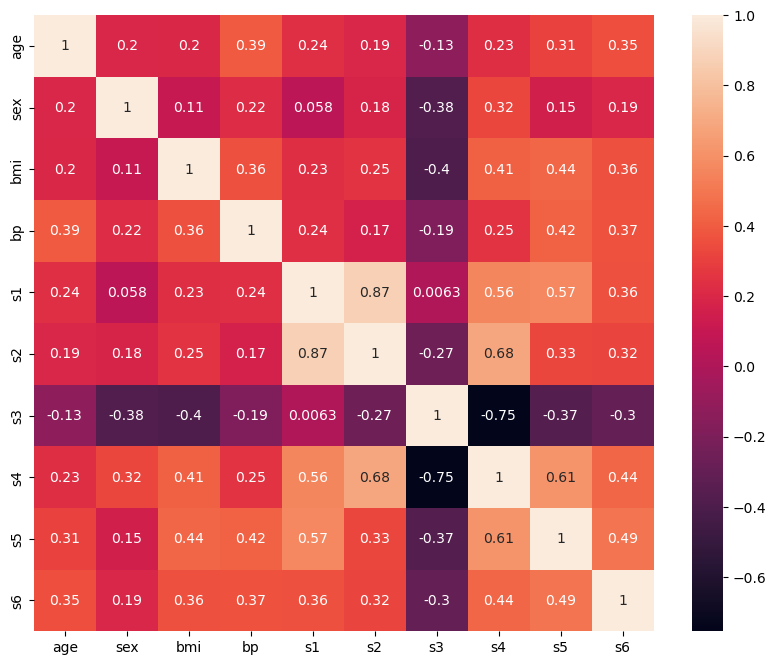

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 8))
sns.heatmap(X_train.corr(), annot=True)

In [12]:
from sklearn.tree import DecisionTreeRegressor
regressor = DecisionTreeRegressor()
regressor.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


# Hyperparameter Tuning

In [13]:
params = {
    'criterion':["squared_error", "absolute_error", "poisson"],\
    'max_depth': [1,2,3,4,5,10,15,20,25],
    'max_features': ["auto", "sqrt", "log2"],
    'splitter': ['best', 'random']
}

In [14]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(regressor, params, cv =5, scoring='neg_mean_squared_error')

In [15]:
import warnings
warnings.filterwarnings('ignore')
grid.fit(X_train, y_train)

,estimator,DecisionTreeRegressor()
,param_grid,"{'criterion': ['squared_error', 'absolute_error', ...], 'max_depth': [1, 2, ...], 'max_features': ['auto', 'sqrt', ...], 'splitter': ['best', 'random']}"
,scoring,'neg_mean_squared_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'poisson'


In [16]:
grid.best_params_


{'criterion': 'poisson',
 'max_depth': 4,
 'max_features': 'log2',
 'splitter': 'best'}

In [17]:
y_pred = grid.predict(X_test)

In [18]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [19]:
print('r2_score:', r2_score(y_test, y_pred))
print('mean_squared_error:', mean_squared_error(y_test, y_pred))
print('mean_absolute_error:', mean_absolute_error(y_test, y_pred))

r2_score: 0.23698480937491484
mean_squared_error: 4828.1091667877745
mean_absolute_error: 56.80332876609873


In [20]:
selectedModel = DecisionTreeRegressor(criterion='poisson', max_depth=4, max_features='log2', splitter='best')

In [21]:
selectedModel.fit(X_train, y_train)

,criterion,'poisson'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'log2'
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


[Text(0.5431034482758621, 0.9, 'x[9] <= 0.034\npoisson = 18.919\nsamples = 309\nvalue = 152.738'),
 Text(0.27586206896551724, 0.7, 'x[6] <= -0.019\npoisson = 16.408\nsamples = 241\nvalue = 136.029'),
 Text(0.40948275862068967, 0.8, 'True  '),
 Text(0.13793103448275862, 0.5, 'x[8] <= -0.043\npoisson = 14.102\nsamples = 82\nvalue = 170.988'),
 Text(0.06896551724137931, 0.3, 'x[1] <= 0.003\npoisson = 11.177\nsamples = 8\nvalue = 109.875'),
 Text(0.034482758620689655, 0.1, 'poisson = 12.426\nsamples = 4\nvalue = 133.75'),
 Text(0.10344827586206896, 0.1, 'poisson = 4.699\nsamples = 4\nvalue = 86.0'),
 Text(0.20689655172413793, 0.3, 'x[1] <= 0.003\npoisson = 12.939\nsamples = 74\nvalue = 177.595'),
 Text(0.1724137931034483, 0.1, 'poisson = 11.109\nsamples = 21\nvalue = 204.095'),
 Text(0.2413793103448276, 0.1, 'poisson = 12.6\nsamples = 53\nvalue = 167.094'),
 Text(0.41379310344827586, 0.5, 'x[3] <= 0.037\npoisson = 14.206\nsamples = 159\nvalue = 118.0'),
 Text(0.3448275862068966, 0.3, 'x[3]

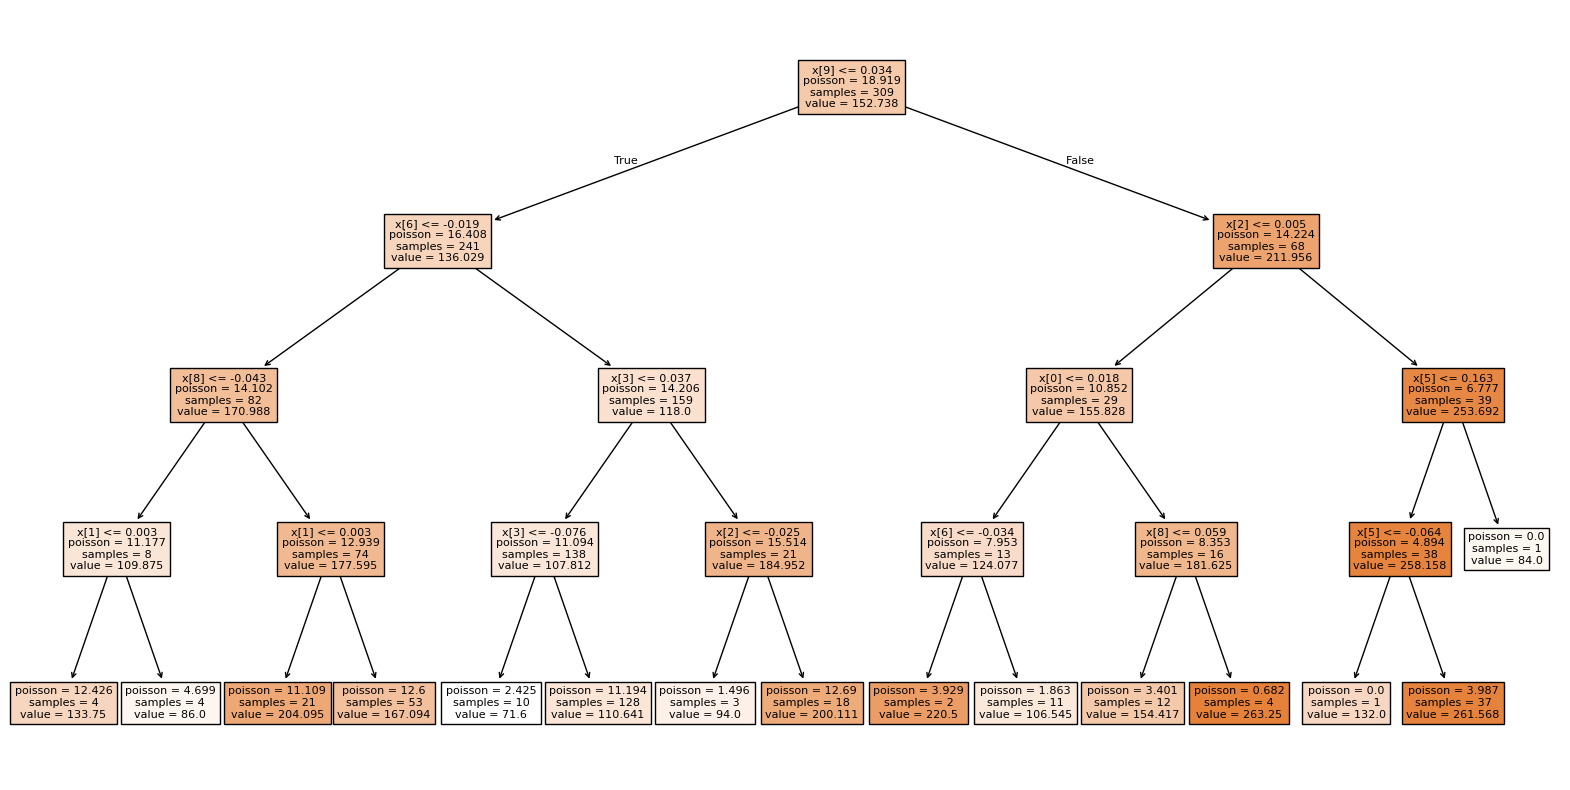

In [22]:
from sklearn import tree
plt.figure(figsize=(20, 10))
tree.plot_tree(selectedModel, filled=True)